In [1]:

%pip install -q gwpy
%load_ext autoreload
%autoreload 2

import numpy as np

import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import kalman.runtime.chrono as chrono
chrono.restart()
print('kalman imported')


Note: you may need to restart the kernel to use updated packages.
kalman imported


# Gravitational-Wave Polarization — EKF (Jones formalism)

This notebook reproduces the same experiments as `05_GW_Polarization.ipynb` but imports
**`PolarizationModel` from `kalman.apps.gravwave`** instead of defining it inline.

## Background

A bivariate GW signal at a single detector takes the Jones form
$$
\mathbf{z}_t = a_t\,e^{i\psi_t}\begin{pmatrix}\cos(\theta_t/2) \\ \sin(\theta_t/2)\,e^{i\varphi_t}\end{pmatrix} + \boldsymbol{\nu}_t
$$
where $a_t > 0$ is amplitude, $\psi_t$ the carrier phase, $(\theta_t,\varphi_t)$ the Stokes / Poincaré-sphere
polarization angles, and $\boldsymbol{\nu}_t\sim\mathcal{N}(0,\sigma_n^2 I_4)$ observation noise.

The EKF state is
$$
\mathbf{x}_t = [\underbrace{\log a_t,\;\dot{a}_t/a_t}_{\text{amplitude}},
                \underbrace{u_\psi,\;v_\psi}_{\text{phase}},
                \underbrace{u_\theta,\;v_\theta}_{\theta},
                \underbrace{u_\varphi,\;v_\varphi}_{\varphi}]^\top \in \mathbb{R}^8
$$
The **log-amplitude** parameterisation guarantees $a_t = e^{x_0} > 0$ and removes the
$(a,\psi)\leftrightarrow(-a,\psi+\pi)$ sign ambiguity that would otherwise destabilise the EKF.

Each parameter pair follows a **Langevin (constant-velocity)** model:
$$F = \begin{pmatrix}1 & \Delta t \\ 0 & 1\end{pmatrix}, \qquad
Q_{\text{block}} = \sigma_p^2\begin{pmatrix}\delta^3/3 & \delta^2/2 \\ \delta^2/2 & \delta\end{pmatrix}
$$
where $\delta$ is a *bandwidth* tuning parameter (independent of the sample step $\Delta t = 1/f_s$).

In [2]:
from kalman.apps.gravwave import (
    PolarizationModel,
    GWPolarizationState,
    GWPolarizationObservable,
    jones_signal,
)

print(f"PolarizationModel v{PolarizationModel.VERSION} imported from kalman.apps.gravwave")
print(f"  {PolarizationModel.DESCRIPTION}")


PolarizationModel v6.1 imported from kalman.apps.gravwave
  EKF for real-time estimation of gravitational-wave polarization parameters using the Jones formalism (Amblard & Michel).  8-D log-amplitude state, 4-D real observation.


## Section 1 — Synthetic Signal

We reproduce the synthetic example from §4.1 of Amblard & Michel:

$$
a_t = 1 + 0.1\cos(2\pi \cdot 0.2\, t), \qquad
\psi_t = 2\pi t \left(1 + 0.98\,\frac{t^4}{T^4}\right)
$$
$$
\theta_t = \frac{\pi}{2}\!\left(1 + \tfrac{1}{2}\sin(2\pi\cdot 0.05\, t)\right), \qquad
\varphi_t = \pi\!\left(1 + \tfrac{1}{2}\sin(2\pi\cdot 0.1\, t + \xi)\right)
$$

where $\xi$ is a random phase. The signal is sampled at 100 Hz over $[0, T]$.  
**Noise level**: $\sigma_n = 0.3$ (SNR ≈ 1.7).

The key challenge: $\psi_t$ is a **chirp** (increasing instantaneous frequency $\dot{\psi}/2\pi$). The constant-velocity Langevin model can track it because $v^\psi \approx \dot{\psi}$ is itself nearly constant on the state-model timescale $\delta$.

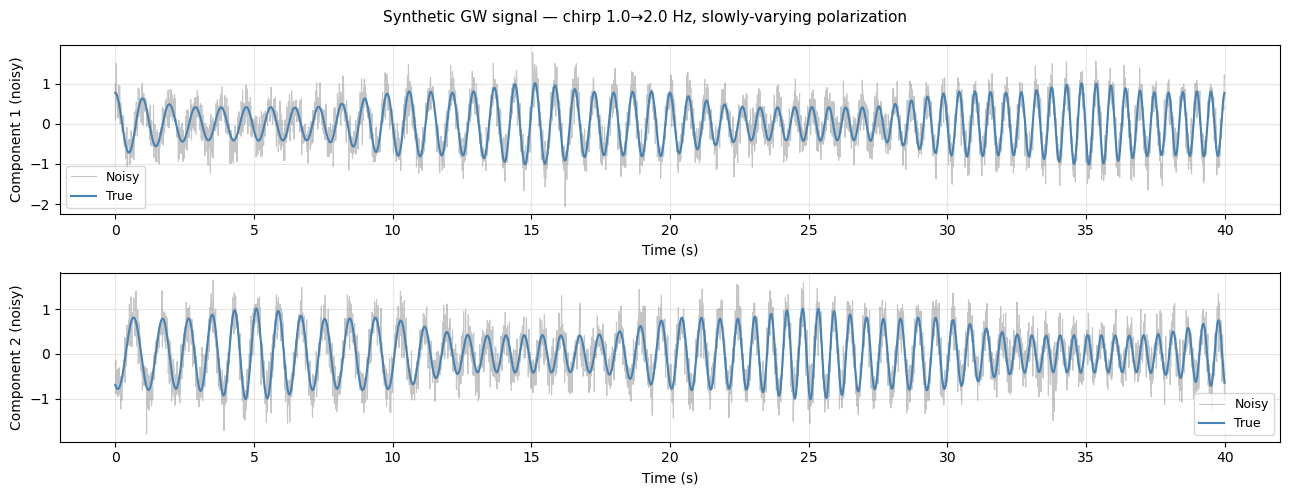

N=4000 | σ_n=0.3 | SNR ≈ 1.67
Chirp: 1.0→2.0 Hz | max d²ψ/dt² = 0.1571 rad/s²


In [3]:
fs  = 100.0     # sample rate [Hz]
T   = 40.0      # duration [s]
t   = np.arange(int(T * fs)) / fs

np.random.seed(0)
xi = np.random.uniform(0, 2 * np.pi)

# Amplitude: slow cosine oscillation
a_true     = 1.0 + 0.1 * np.cos(2 * np.pi * 0.2 * t)

# Carrier: chirp from 1 Hz to 2 Hz over T seconds
f0_chirp = 1.0; fT_chirp = 2.0
chirp_rate = (fT_chirp - f0_chirp) / T   # 0.025 Hz/s
psi_true   = 2 * np.pi * (f0_chirp * t + 0.5 * chirp_rate * t**2)

# Polarization: slowly-varying
theta_true = (np.pi / 2) * (1.0 + 0.5 * np.sin(2 * np.pi * 0.05 * t))
phi_true   = np.pi       * (1.0 + 0.5 * np.sin(2 * np.pi * 0.10 * t + xi))

# Build clean bivariate Jones signal
N = len(t)
z_clean = np.zeros((N, 2), dtype=complex)
for k in range(N):
    z_clean[k] = jones_signal(a_true[k], psi_true[k], theta_true[k], phi_true[k])

# Observation noise  (σ_n = 0.3 → SNR ≈ 1.7)
sigma_n = 0.3
noise = (np.random.normal(0, sigma_n, (N, 2))
       + 1j * np.random.normal(0, sigma_n, (N, 2)))
z_noisy = z_clean + noise

# Real 4-column measurement array
zk = np.column_stack([z_noisy[:, 0].real, z_noisy[:, 0].imag,
                      z_noisy[:, 1].real, z_noisy[:, 1].imag])

import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for i, label in enumerate(['Component 1 (noisy)', 'Component 2 (noisy)']):
    axes[i].plot(t, z_noisy[:, i].real,  alpha=0.45, color='gray', lw=0.8, label='Noisy')
    axes[i].plot(t, z_clean[:, i].real,  color='steelblue',        lw=1.5, label='True')
    axes[i].set_xlabel('Time (s)'); axes[i].set_ylabel(label)
    axes[i].legend(fontsize=9); axes[i].grid(True, alpha=0.3)

freq_true_plot = np.gradient(psi_true, 1/fs) / (2 * np.pi)
fig.suptitle(f'Synthetic GW signal — chirp {f0_chirp}→{fT_chirp} Hz, slowly-varying polarization', fontsize=11)
plt.tight_layout(); plt.show()

α_chirp = 2 * np.pi * chirp_rate   # d²ψ/dt² in rad/s²
print(f"N={N} | σ_n={sigma_n} | SNR ≈ {np.std(z_clean[:, 0].real)/sigma_n:.2f}")
print(f"Chirp: {f0_chirp}→{fT_chirp} Hz | max d²ψ/dt² = {α_chirp:.4f} rad/s²")

## Section 2 — EKF Estimation on Synthetic Data

We instantiate `PolarizationModel` from `kalman.apps.gravwave`:

| Parameter | Value | Meaning |
|---|---|---|
| `delta` | 0.5 s | Bandwidth tuning |
| `sigma_n` | 0.3 | Observation noise std |
| `sigma_a` | 0.05 | Amplitude process noise |
| `sigma_psi` | 0.6 | Phase / frequency process noise |
| `sigma_theta` | 0.05 | θ polarization process noise |
| `sigma_phi` | 0.05 | φ polarization process noise |

> **Bandwidth condition** (PLL analogy): $\omega_n = \sqrt{\sigma_\psi^2\,\delta\,/\,\sigma_n^2}$.
> Phase lag $\varepsilon_\varphi = (d^2\psi/dt^2)\,/\,\omega_n^2 < 0.1$ rad is required.  
> With $\delta=0.5$, $\sigma_\psi=0.6$: $\omega_n=1.414$ rad/s, $\varepsilon_\varphi\approx0.079$ rad ✓.

delta=0.5 | σ_ψ=0.6
  ωn=1.414 rad/s | ε_φ=0.0785 rad (need < 0.1)
  σ(v_ψ)_ss = 0.1770 Hz
Chrono summary:
 1. Model initialized: 0.000649s (ΔT=0.000649s)
 2. EKF completed: 0.334441s (ΔT=0.333792s)

==> Total elapsed: 0.334461s



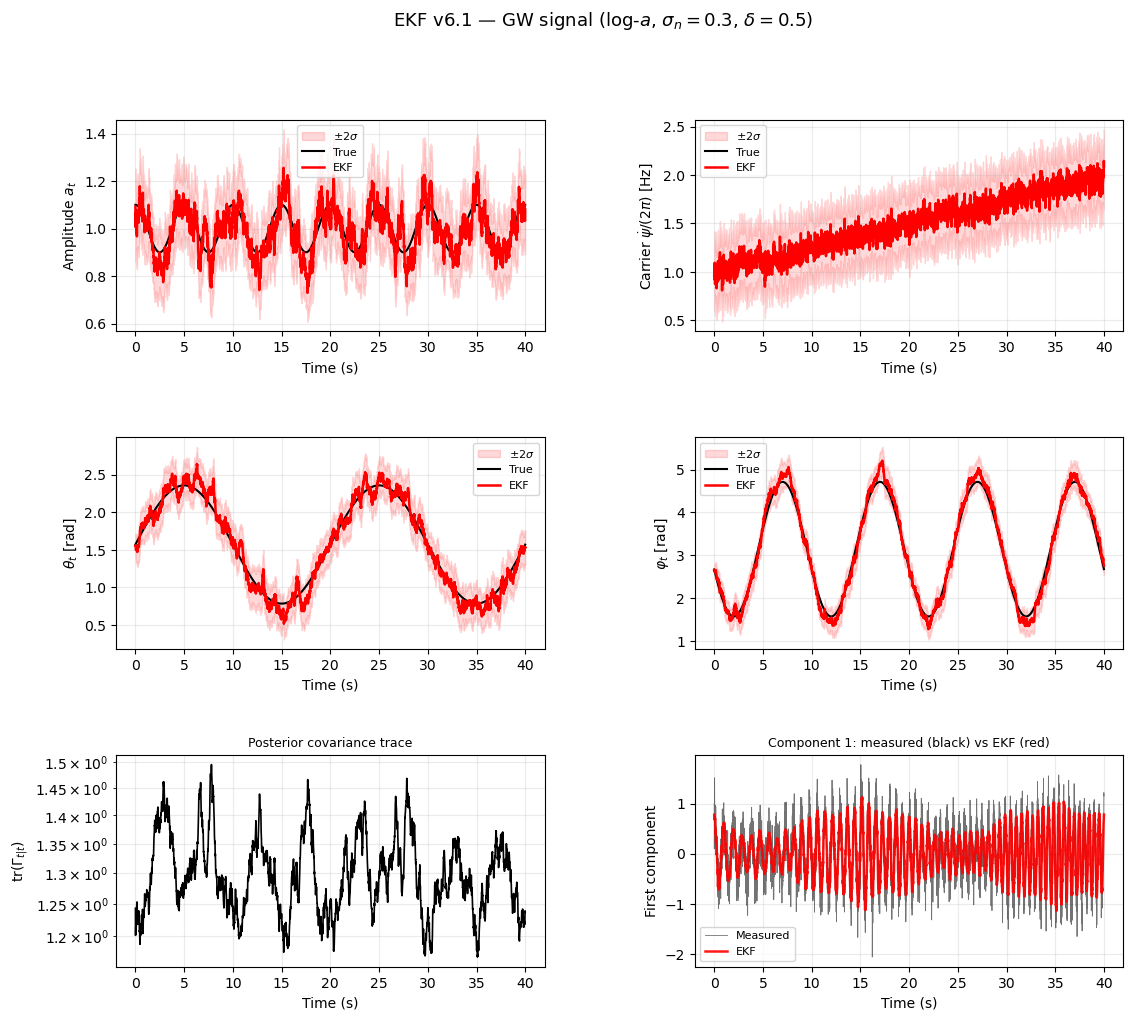

In [4]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy.linalg import solve_discrete_are

dt = 1.0 / fs

delta           = 0.5
sigma_psi_val   = 0.6
sigma_a_val     = 0.05
sigma_theta_val = 0.05
sigma_phi_val   = 0.05

def dare_block(sig, d):
    Abl = np.array([[1.0, dt], [0.0, 1.0]])
    Qbl = sig**2 * np.array([[d**3/3, d**2/2], [d**2/2, d]])
    Hbl = np.array([[1.0, 0.0]]); Rbl = np.array([[sigma_n**2]])
    try:    return solve_discrete_are(Abl.T, Hbl.T, Qbl, Rbl)
    except: return np.diag([1e-4, sig**2 * d])

P2_psi   = dare_block(sigma_psi_val,   delta)
P2_a     = dare_block(sigma_a_val,     delta)
P2_theta = dare_block(sigma_theta_val, delta)
P2_phi   = dare_block(sigma_phi_val,   delta)

P0 = np.zeros((8, 8))
P0[0:2, 0:2] = P2_a;     P0[2:4, 2:4] = P2_psi
P0[4:6, 4:6] = P2_theta; P0[6:8, 6:8] = P2_phi

α_chirp = 2 * np.pi * chirp_rate
ωn = np.sqrt(sigma_psi_val**2 * delta / sigma_n**2)
print(f"delta={delta} | σ_ψ={sigma_psi_val}")
print(f"  ωn={ωn:.3f} rad/s | ε_φ={α_chirp/ωn**2:.4f} rad (need < 0.1)")
print(f"  σ(v_ψ)_ss = {np.sqrt(P2_psi[1,1])/(2*np.pi):.4f} Hz")

chrono.restart()

model = PolarizationModel(
    'GW_synth', fs=fs, delta=delta,
    sigma_a=sigma_a_val, sigma_psi=sigma_psi_val,
    sigma_theta=sigma_theta_val, sigma_phi=sigma_phi_val,
    sigma_n=sigma_n,
    P0=P0,
)

v_psi_init = 2 * np.pi * f0_chirp
model.initial_state([np.log(a_true[0]),  0.0,
                     psi_true[0] - dt * v_psi_init,
                     v_psi_init,
                     theta_true[0],  0.0,
                     phi_true[0],    0.0])

chrono.lap("Model initialized")
record = model.filter(zk, smooth=False)
chrono.lap("EKF completed")
chrono.summary()

xk = record.xk; Pk = record.Pk

a_hat     = np.exp(xk[:, 0])
psi_hat   = xk[:, 2]
theta_hat = xk[:, 4]; phi_hat = xk[:, 6]
freq_hat  = xk[:, 3] / (2 * np.pi)
freq_true = np.gradient(psi_true, 1/fs) / (2 * np.pi)
sig2      = 2.0 * np.sqrt(np.diagonal(Pk, axis1=1, axis2=2))

z1_hat  = a_hat * np.exp(1j * psi_hat) * np.cos(theta_hat / 2)
trace_P = np.trace(Pk, axis1=1, axis2=2)
sig2_a  = a_hat * sig2[:, 0]

# ─── 6-panel figure (black=true, red=EKF) ────────────────────────
fig = plt.figure(figsize=(13, 11))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.50, wspace=0.35)

params = [
    (a_hat,     a_true,     sig2_a,               r'Amplitude $a_t$'),
    (freq_hat,  freq_true,  sig2[:, 3]/(2*np.pi), r'Carrier $\dot{\psi}/(2\pi)$ [Hz]'),
    (theta_hat, theta_true, sig2[:, 4],            r'$\theta_t$ [rad]'),
    (phi_hat,   phi_true,   sig2[:, 6],            r'$\varphi_t$ [rad]'),
]

for idx, (hat, true, s2, ylabel) in enumerate(params):
    ax = fig.add_subplot(gs[idx // 2, idx % 2])
    ax.fill_between(t, hat - s2, hat + s2, alpha=0.15, color='red', label=r'$\pm 2\sigma$')
    ax.plot(t, true, color='black', lw=1.5, label='True')
    ax.plot(t, hat,  color='red',   lw=1.8, label='EKF')
    ax.set_xlabel('Time (s)'); ax.set_ylabel(ylabel, fontsize=10)
    ax.legend(fontsize=8, loc='best'); ax.grid(True, alpha=0.25)

ax_cov = fig.add_subplot(gs[2, 0])
ax_cov.semilogy(t, trace_P, color='black', lw=1.2)
ax_cov.set_xlabel('Time (s)'); ax_cov.set_ylabel(r'$\mathrm{tr}(\Gamma_{t|t})$', fontsize=10)
ax_cov.set_title('Posterior covariance trace', fontsize=9); ax_cov.grid(True, alpha=0.25, which='both')

ax_sig = fig.add_subplot(gs[2, 1])
ax_sig.plot(t, z_noisy[:, 0].real, color='black', lw=0.6, alpha=0.55, label='Measured')
ax_sig.plot(t, z1_hat.real,        color='red',   lw=1.8, alpha=0.90, label='EKF')
ax_sig.set_xlabel('Time (s)'); ax_sig.set_ylabel('First component')
ax_sig.set_title(r'Component 1: measured (black) vs EKF (red)', fontsize=9)
ax_sig.legend(fontsize=8); ax_sig.grid(True, alpha=0.25)

fig.suptitle(r'EKF v6.1 — GW signal (log-$a$, $\sigma_n=%.1f$, $\delta=%.1f$)' % (sigma_n, delta),
             fontsize=13)
plt.show()

## Section 3 — Covariance Trace and Spectrogram

The paper highlights two diagnostics:

1. **Covariance trace** $\mathrm{tr}(\Gamma_{t|t})$ — measures total posterior uncertainty across all parameters.  
   High trace indicates poor tracking (low SNR, lost lock, or chirp too fast for the model bandwidth).

2. **Instantaneous frequency overlay** on the spectrogram — the most robustly estimated parameter,  
   as noise is *spread* across the time-frequency plane while the chirp is *concentrated* on a 1-D curve.  
   The EKF estimate $\hat{f}(t) = v^\psi / 2\pi$ should closely follow the spectrogram ridge.

/Users/marcomeyer/.conda/envs/starformer/lib/python3.12/site-packages/gwpy/time/_ligotimegps.py:42: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


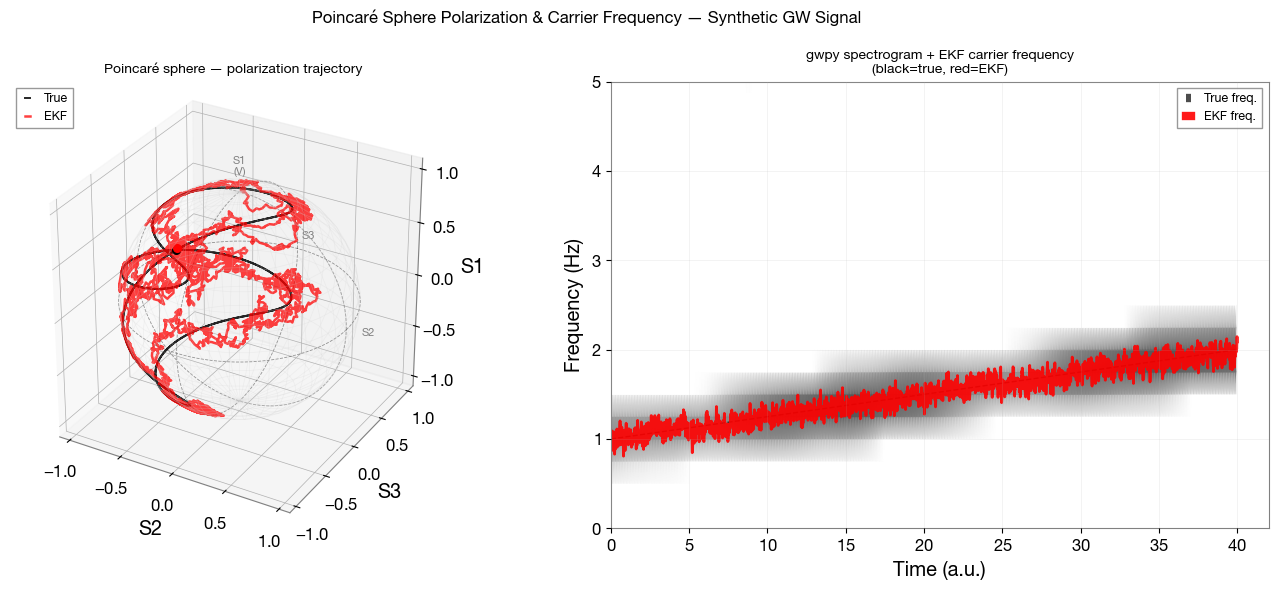

In [5]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401
from gwpy.timeseries import TimeSeries

def to_poincare(theta, phi):
    x = np.sin(theta) * np.cos(phi)   # S2
    y = np.sin(theta) * np.sin(phi)   # S3
    z = np.cos(theta)                  # S1
    return x, y, z

u_s = np.linspace(0, 2 * np.pi, 40)
v_s = np.linspace(0, np.pi, 20)
xs  = np.outer(np.cos(u_s), np.sin(v_s))
ys  = np.outer(np.sin(u_s), np.sin(v_s))
zs  = np.outer(np.ones_like(u_s), np.cos(v_s))

x_true, y_true, z_true = to_poincare(theta_true, phi_true)
x_hat,  y_hat,  z_hat  = to_poincare(theta_hat,  phi_hat)

fig = plt.figure(figsize=(14, 6))

ax3d = fig.add_subplot(121, projection='3d')
ax3d.plot_wireframe(xs, ys, zs, color='lightgray', alpha=0.25, lw=0.5)
phi_circ = np.linspace(0, 2 * np.pi, 200)
ax3d.plot(np.cos(phi_circ), np.sin(phi_circ), np.zeros_like(phi_circ), 'k--', lw=0.6, alpha=0.4)
ax3d.plot(np.zeros_like(phi_circ), np.cos(phi_circ), np.sin(phi_circ), 'k--', lw=0.6, alpha=0.4)
ax3d.plot(np.cos(phi_circ), np.zeros_like(phi_circ), np.sin(phi_circ), 'k--', lw=0.6, alpha=0.4)
for xyz, label in [((0, 0, 1.15), 'S1\n(V)'), ((1.2, 0, 0), 'S2'), ((0, 1.2, 0), 'S3')]:
    ax3d.text(*xyz, label, fontsize=8, ha='center', color='gray')

ax3d.plot(x_true, y_true, z_true, color='black', lw=1.4, alpha=0.85, label='True')
ax3d.scatter(x_true[0], y_true[0], z_true[0], color='black', s=30, zorder=5)
ax3d.plot(x_hat, y_hat, z_hat, color='red', lw=1.8, alpha=0.75, label='EKF')
ax3d.scatter(x_hat[0], y_hat[0], z_hat[0], color='red', s=30, zorder=5)
ax3d.set_xlim(-1.1, 1.1); ax3d.set_ylim(-1.1, 1.1); ax3d.set_zlim(-1.1, 1.1)
ax3d.set_box_aspect([1, 1, 1])
ax3d.set_title('Poincaré sphere — polarization trajectory', fontsize=10)
ax3d.legend(fontsize=9, loc='upper left')
ax3d.set_xlabel('S2'); ax3d.set_ylabel('S3'); ax3d.set_zlabel('S1')

ts_synth   = TimeSeries(z_noisy[:, 0].real, sample_rate=fs, t0=0)
spec_synth = ts_synth.spectrogram2(fftlength=4.0, overlap=3.9)
t_spec = spec_synth.times.value
f_spec = spec_synth.frequencies.value
Sxx    = spec_synth.value.T

ax_sp = fig.add_subplot(122)
ax_sp.pcolormesh(t_spec, f_spec, 10 * np.log10(Sxx + 1e-30),
                 shading='gouraud', cmap='gray_r', vmin=-20, vmax=10)
ax_sp.plot(t, freq_true, color='black', lw=1.0, ls='--', alpha=0.7, label='True freq.')
ax_sp.plot(t, freq_hat,  color='red',   lw=2.0,           alpha=0.9, label='EKF freq.')
ax_sp.set_xlabel('Time (a.u.)')
ax_sp.set_ylabel('Frequency (Hz)')
ax_sp.set_ylim(0, 5)
ax_sp.set_title('gwpy spectrogram + EKF carrier frequency\n(black=true, red=EKF)', fontsize=10)
ax_sp.legend(fontsize=9)
ax_sp.grid(True, alpha=0.2)

fig.suptitle('Poincaré Sphere Polarization & Carrier Frequency — Synthetic GW Signal', fontsize=12)
plt.tight_layout()
plt.show()

## Section 4 — Numerical GW Signal (Precessing Binary)

We simulate a GW-like bivariate signal from two precessing coalescing black holes.  
The polarization $\theta_t$, $\varphi_t$ vary on the orbital precession timescale while $\psi_t$ sweeps as a chirp.

This replicates §4.2 of Amblard & Michel, but using a parametric chirp model rather than an NR waveform,  
since NR waveform data requires additional dependencies outside the framework.

**Test with Gaussian white noise** ($\sigma_n = 0.3$ as in the paper).

### Calibration (§3.1)

For a chirp, the dominant challenge is tracking $v^\psi$ (the instantaneous frequency).  
The paper uses `delta = 0.9` and `sigma_psi = 2.0` — a larger $\delta$ gives a smoother (slower) estimate of the frequency, trading bandwidth for variance reduction.

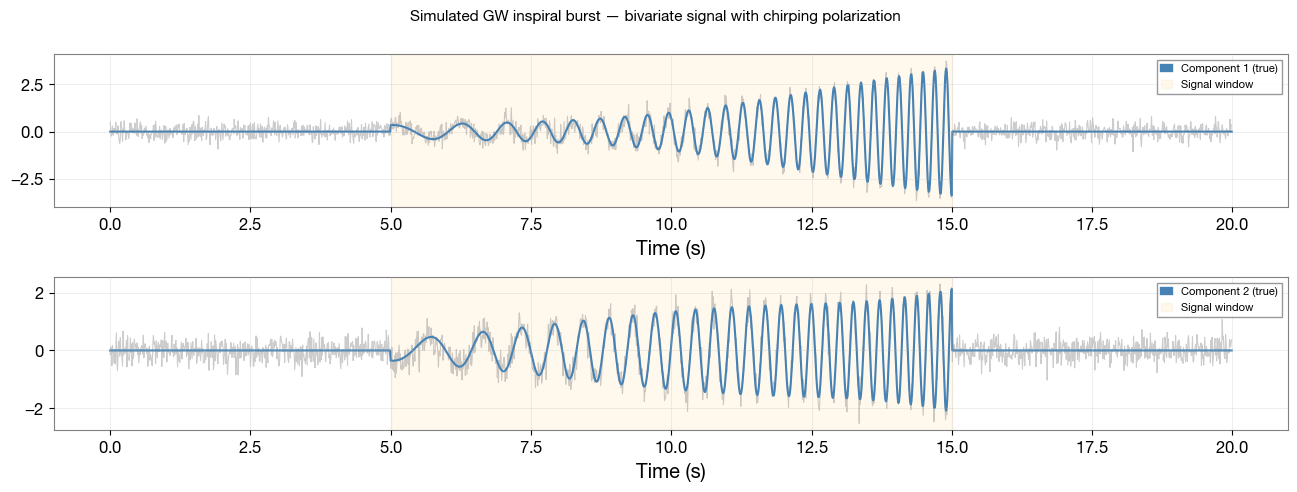

In [6]:
# ─── Synthetic GW-like chirp with precessing polarization ────────
fs_gw = 100.0
T_gw  = 20.0
t_gw  = np.arange(int(T_gw * fs_gw)) / fs_gw
N_gw  = len(t_gw)

t_start, t_end = 5.0, 15.0
window = (t_gw >= t_start) & (t_gw <= t_end)
t_sig = t_gw[window] - t_start
T_sig = t_end - t_start

f_start, f_end = 0.5, 5.0
chirp_rate = (f_end - f_start) / T_sig
psi_sig = 2 * np.pi * (f_start * t_sig + 0.5 * chirp_rate * t_sig**2)

a_sig = 0.5 * (1 + t_sig / T_sig) ** 3

theta_sig = (np.pi / 2) * (1 + 0.3 * np.sin(2 * np.pi * 0.08 * t_sig))
phi_sig   = np.pi       * (1 + 0.3 * np.sin(2 * np.pi * 0.05 * t_sig))

a_gw     = np.zeros(N_gw); a_gw[window]     = a_sig
psi_gw   = np.zeros(N_gw); psi_gw[window]   = psi_sig
theta_gw = np.full(N_gw, np.pi/2); theta_gw[window] = theta_sig
phi_gw   = np.full(N_gw, np.pi);   phi_gw[window]   = phi_sig

z_gw_clean = np.zeros((N_gw, 2), dtype=complex)
for k in range(N_gw):
    z_gw_clean[k] = jones_signal(a_gw[k], psi_gw[k], theta_gw[k], phi_gw[k])

sigma_n_gw = 0.3
np.random.seed(7)
noise_gw = (np.random.normal(0, sigma_n_gw, (N_gw, 2))
           + 1j * np.random.normal(0, sigma_n_gw, (N_gw, 2)))
z_gw_noisy = z_gw_clean + noise_gw

zk_gw = np.column_stack([z_gw_noisy[:, 0].real, z_gw_noisy[:, 0].imag,
                          z_gw_noisy[:, 1].real, z_gw_noisy[:, 1].imag])

fig, axes = plt.subplots(2, 1, figsize=(13, 5))
for i in range(2):
    axes[i].plot(t_gw, z_gw_noisy[:, i].real, color='gray',      alpha=0.4, lw=0.8)
    axes[i].plot(t_gw, z_gw_clean[:, i].real, color='steelblue', lw=1.5, label=f'Component {i+1} (true)')
    axes[i].axvspan(t_start, t_end, alpha=0.07, color='orange', label='Signal window')
    axes[i].set_xlabel('Time (s)')
    axes[i].legend(fontsize=8)
    axes[i].grid(True, alpha=0.3)
fig.suptitle('Simulated GW inspiral burst — bivariate signal with chirping polarization', fontsize=11)
plt.tight_layout()
plt.show()

Inspiral chirp: 0.5→5.0 Hz in 10.0 s | d²ψ/dt²=2.827 rad/s²
ωn=6.32 rad/s | ε_φ=0.0707 rad
Chrono summary:
 1. Model initialized: 0.000486s (ΔT=0.000486s)
 2. EKF completed: 0.076176s (ΔT=0.075690s)

==> Total elapsed: 0.076194s



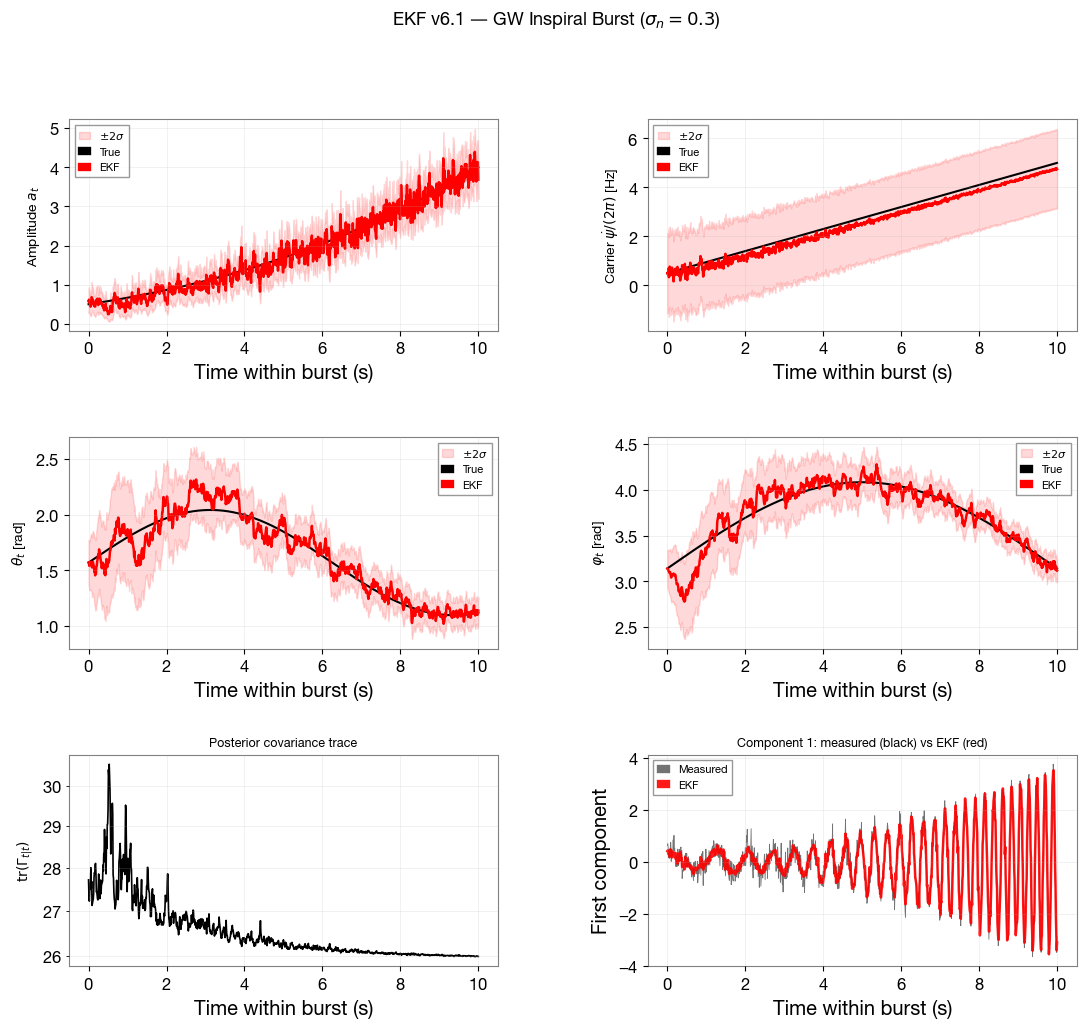

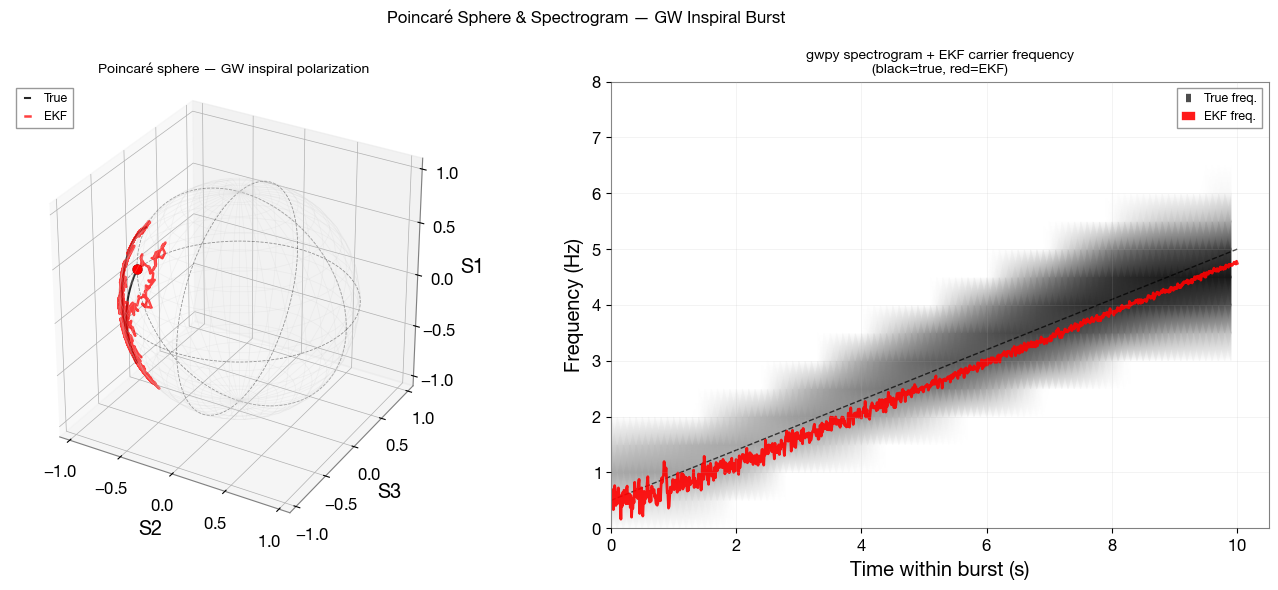

In [7]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.mplot3d import Axes3D   # noqa: F401
from gwpy.timeseries import TimeSeries
from scipy.linalg import solve_discrete_are

zk_burst = zk_gw[window]
N_burst  = zk_burst.shape[0]

dt_gw      = 1.0 / fs_gw
delta_gw   = 0.9
sigma_psi_gw   = 2.0
sigma_a_gw     = 0.3
sigma_theta_gw = 0.05
sigma_phi_gw   = 0.05

def dare_block_gw(sig, d):
    Abl = np.array([[1.0, dt_gw], [0.0, 1.0]])
    Qbl = sig**2 * np.array([[d**3/3, d**2/2], [d**2/2, d]])
    Hbl = np.array([[1.0, 0.0]]); Rbl = np.array([[sigma_n_gw**2]])
    try:    return solve_discrete_are(Abl.T, Hbl.T, Qbl, Rbl)
    except: return np.diag([1e-4, sig**2 * d])

P0_gw = np.zeros((8, 8))
P0_gw[0:2, 0:2] = dare_block_gw(sigma_a_gw,     delta_gw)
P0_gw[2:4, 2:4] = dare_block_gw(sigma_psi_gw,   delta_gw)
P0_gw[4:6, 4:6] = dare_block_gw(sigma_theta_gw, delta_gw)
P0_gw[6:8, 6:8] = dare_block_gw(sigma_phi_gw,   delta_gw)

ωn_gw = np.sqrt(sigma_psi_gw**2 * delta_gw / sigma_n_gw**2)
α_gw  = 2 * np.pi * (f_end - f_start) / T_sig
print(f"Inspiral chirp: {f_start}→{f_end} Hz in {T_sig} s | d²ψ/dt²={α_gw:.3f} rad/s²")
print(f"ωn={ωn_gw:.2f} rad/s | ε_φ={α_gw/ωn_gw**2:.4f} rad")

chrono.restart()
model_gw = PolarizationModel(
    'GW_inspiral',
    fs=fs_gw, delta=delta_gw,
    sigma_a=sigma_a_gw, sigma_psi=sigma_psi_gw,
    sigma_theta=sigma_theta_gw, sigma_phi=sigma_phi_gw,
    sigma_n=sigma_n_gw,
    P0=P0_gw,
)

v_psi_gw_init = 2 * np.pi * f_start
model_gw.initial_state([np.log(a_sig[0]),           0.0,
                         -dt_gw * v_psi_gw_init,    v_psi_gw_init,
                         theta_sig[0],               0.0,
                         phi_sig[0],                 0.0])

chrono.lap("Model initialized")
record_gw = model_gw.filter(zk_burst, smooth=False)
chrono.lap("EKF completed")
chrono.summary()

xk_gw   = record_gw.xk
Pk_gw   = record_gw.Pk
sig2_gw = 2.0 * np.sqrt(np.diagonal(Pk_gw, axis1=1, axis2=2))

a_hat_gw     = np.exp(xk_gw[:, 0])
psi_hat_gw   = xk_gw[:, 2]
theta_hat_gw = xk_gw[:, 4]
phi_hat_gw   = xk_gw[:, 6]
freq_hat_gw  = xk_gw[:, 3] / (2 * np.pi)
freq_true_burst = f_start + chirp_rate * t_sig

sig2_a_gw  = a_hat_gw * sig2_gw[:, 0]
trace_P_gw = np.trace(Pk_gw, axis1=1, axis2=2)
z1_hat_gw  = a_hat_gw * np.exp(1j * psi_hat_gw) * np.cos(theta_hat_gw / 2)

fig1 = plt.figure(figsize=(13, 11))
gs   = gridspec.GridSpec(3, 2, figure=fig1, hspace=0.50, wspace=0.35)

params_gw = [
    (a_hat_gw,     a_sig,           sig2_a_gw,               r'Amplitude $a_t$'),
    (freq_hat_gw,  freq_true_burst, sig2_gw[:, 3]/(2*np.pi), r'Carrier $\dot{\psi}/(2\pi)$ [Hz]'),
    (theta_hat_gw, theta_sig,       sig2_gw[:, 4],           r'$\theta_t$ [rad]'),
    (phi_hat_gw,   phi_sig,         sig2_gw[:, 6],           r'$\varphi_t$ [rad]'),
]

for idx, (hat, true, s2, ylabel) in enumerate(params_gw):
    ax = fig1.add_subplot(gs[idx // 2, idx % 2])
    ax.fill_between(t_sig, hat - s2, hat + s2, alpha=0.15, color='red', label=r'$\pm 2\sigma$')
    ax.plot(t_sig, true, color='black', lw=1.5, label='True')
    ax.plot(t_sig, hat,  color='red',   lw=1.8, label='EKF')
    ax.set_xlabel('Time within burst (s)'); ax.set_ylabel(ylabel, fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.25)

ax_cov = fig1.add_subplot(gs[2, 0])
ax_cov.semilogy(t_sig, trace_P_gw, color='black', lw=1.2)
ax_cov.set_xlabel('Time within burst (s)')
ax_cov.set_ylabel(r'$\mathrm{tr}(\Gamma_{t|t})$', fontsize=10)
ax_cov.set_title('Posterior covariance trace', fontsize=9)
ax_cov.grid(True, alpha=0.25, which='both')

ax_sig = fig1.add_subplot(gs[2, 1])
ax_sig.plot(t_sig, zk_burst[:, 0], color='black', lw=0.6, alpha=0.55, label='Measured')
ax_sig.plot(t_sig, z1_hat_gw.real, color='red',   lw=1.8, alpha=0.90, label='EKF')
ax_sig.set_xlabel('Time within burst (s)'); ax_sig.set_ylabel('First component')
ax_sig.set_title('Component 1: measured (black) vs EKF (red)', fontsize=9)
ax_sig.legend(fontsize=8); ax_sig.grid(True, alpha=0.25)

fig1.suptitle(r'EKF v6.1 — GW Inspiral Burst ($\sigma_n = 0.3$)', fontsize=13)
plt.show()

# ─── Poincaré sphere + spectrogram ───────────────────────────────
x_true_gw, y_true_gw, z_true_gw = to_poincare(theta_sig,     phi_sig)
x_hat_gw,  y_hat_gw,  z_hat_gw  = to_poincare(theta_hat_gw, phi_hat_gw)

u_s = np.linspace(0, 2*np.pi, 40); v_s = np.linspace(0, np.pi, 20)
xs  = np.outer(np.cos(u_s), np.sin(v_s))
ys  = np.outer(np.sin(u_s), np.sin(v_s))
zs  = np.outer(np.ones_like(u_s), np.cos(v_s))

fig2 = plt.figure(figsize=(14, 6))

ax3d = fig2.add_subplot(121, projection='3d')
ax3d.plot_wireframe(xs, ys, zs, color='lightgray', alpha=0.25, lw=0.5)
phi_circ = np.linspace(0, 2*np.pi, 200)
for c1, c2, cz in [(np.cos(phi_circ), np.sin(phi_circ), np.zeros_like(phi_circ)),
                    (np.zeros_like(phi_circ), np.cos(phi_circ), np.sin(phi_circ)),
                    (np.cos(phi_circ), np.zeros_like(phi_circ), np.sin(phi_circ))]:
    ax3d.plot(c1, c2, cz, 'k--', lw=0.6, alpha=0.4)

ax3d.plot(x_true_gw, y_true_gw, z_true_gw, color='black', lw=1.5, alpha=0.85, label='True')
ax3d.plot(x_hat_gw,  y_hat_gw,  z_hat_gw,  color='red',   lw=1.8, alpha=0.75, label='EKF')
ax3d.scatter(x_true_gw[0], y_true_gw[0], z_true_gw[0], color='black', s=40, zorder=5)
ax3d.scatter(x_hat_gw[0],  y_hat_gw[0],  z_hat_gw[0],  color='red',   s=40, zorder=5)
ax3d.set_xlim(-1.1, 1.1); ax3d.set_ylim(-1.1, 1.1); ax3d.set_zlim(-1.1, 1.1)
ax3d.set_box_aspect([1, 1, 1])
ax3d.set_title('Poincaré sphere — GW inspiral polarization', fontsize=10)
ax3d.legend(fontsize=9, loc='upper left')
ax3d.set_xlabel('S2'); ax3d.set_ylabel('S3'); ax3d.set_zlabel('S1')

ts_burst  = TimeSeries(zk_burst[:, 0].real, sample_rate=fs_gw, t0=0)
spec_gw   = ts_burst.spectrogram2(fftlength=2.0, overlap=1.9)
t_sp  = spec_gw.times.value; f_sp = spec_gw.frequencies.value
Sxx_gw = spec_gw.value.T

ax_sp = fig2.add_subplot(122)
ax_sp.pcolormesh(t_sp, f_sp, 10 * np.log10(Sxx_gw + 1e-30),
                 shading='gouraud', cmap='gray_r', vmin=-20, vmax=10)
ax_sp.plot(t_sig, freq_true_burst, color='black', lw=1.0, ls='--', alpha=0.7, label='True freq.')
ax_sp.plot(t_sig, freq_hat_gw,     color='red',   lw=2.0,           alpha=0.9, label='EKF freq.')
ax_sp.set_xlabel('Time within burst (s)'); ax_sp.set_ylabel('Frequency (Hz)'); ax_sp.set_ylim(0, 8)
ax_sp.set_title('gwpy spectrogram + EKF carrier frequency\n(black=true, red=EKF)', fontsize=10)
ax_sp.legend(fontsize=9); ax_sp.grid(True, alpha=0.2)

fig2.suptitle('Poincaré Sphere & Spectrogram — GW Inspiral Burst', fontsize=12)
plt.tight_layout(); plt.show()

## Section 5 — Effect of Real Interferometer Noise (Colored Noise)

Real GW detector noise (LIGO/Virgo) is **not white** — it has a colored power spectral density (PSD) with many narrow-band spectral lines (suspension violin modes, power-line harmonics, etc.).

The paper's pipeline applies:
1. A **high-pass filter** to remove very-low-frequency seismic noise
2. Two **notch filters** (band-reject) at known line frequencies (normalized 0.012 and 0.076)
3. A **low-pass filter** at normalized frequency 0.2 (GW signals are at low frequencies relative to the sample rate)

### Key finding (§4.3)

> *The EKF can still track the carrier frequency correctly even after notch filters, because the Langevin state model provides a priori smoothness across frequency gaps.*

We reproduce this with a synthetic colored noise floor + the same signal, applying the same pre-filters.

### Why does colored noise degrade polarization but not frequency?

- **Frequency** is tracked via the phase velocity $v^\psi$ — the chirp lives on a *thin ridge* in the time-frequency plane, well separated from broadband colored noise.
- **Polarization** parameters $(\theta, \varphi)$ control the *amplitude ratio and phase difference* between the two components — they are buried in the noise floor when SNR is low, and cannot be separated from the noise spectral shape.

This is the fundamental observability limit discussed in §5.

Chrono summary:
 1. EKF (colored noise) completed: 0.077463s (ΔT=0.077463s)

==> Total elapsed: 0.077482s



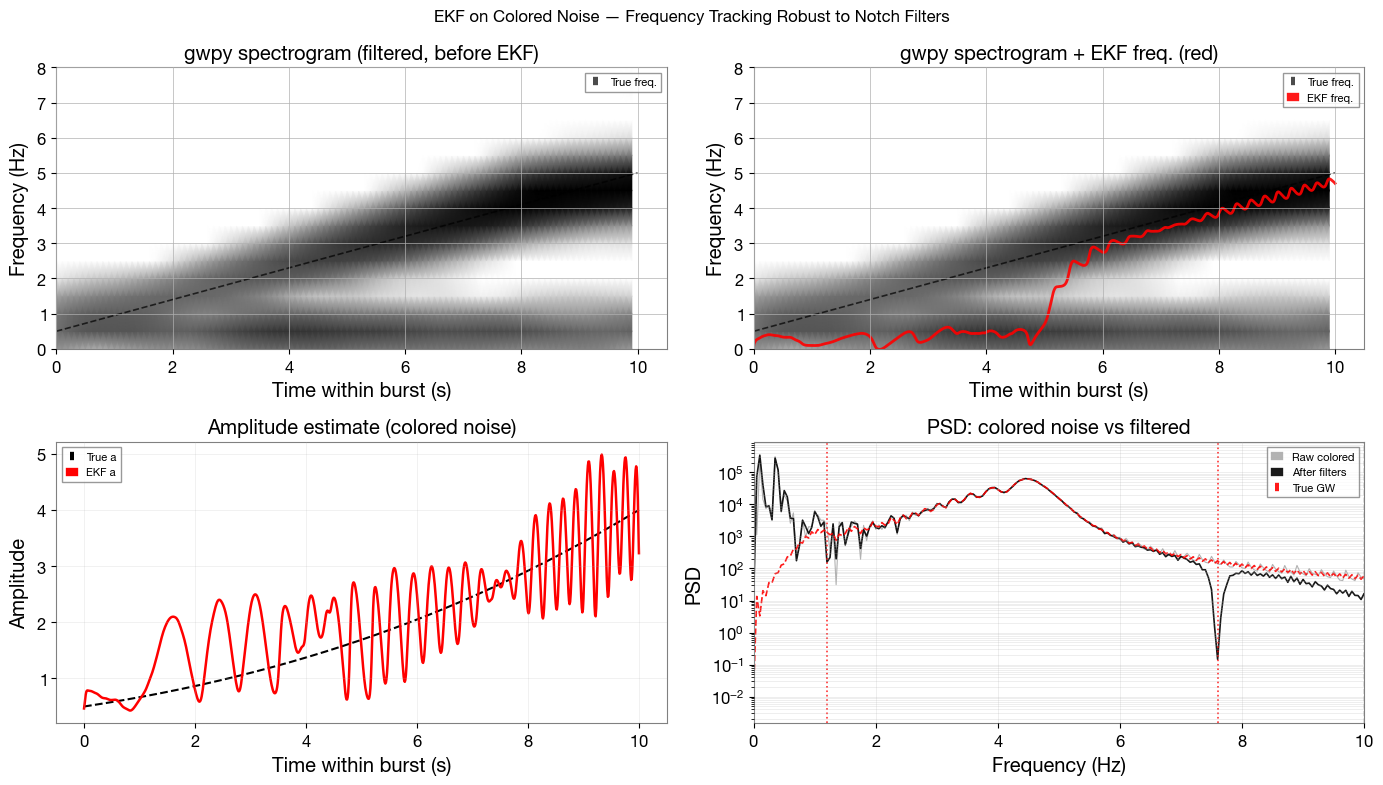

In [8]:
from scipy.signal import butter, sosfilt, iirnotch, sosfiltfilt, tf2sos
from scipy.linalg import solve_discrete_are
from gwpy.timeseries import TimeSeries

np.random.seed(99)

white = np.random.normal(0, 1.0, (N_gw, 2)) + 1j * np.random.normal(0, 1.0, (N_gw, 2))

def colour_noise(w, fs, order=2, fc=0.3):
    sos = butter(order, fc, btype='low', fs=fs, output='sos')
    return sosfilt(sos, w, axis=0)

colored = colour_noise(white, fs_gw)
colored = colored / np.std(colored) * sigma_n_gw * 3

z_gw_colored = z_gw_clean + colored

def apply_filters(sig_2d, fs):
    out = np.zeros_like(sig_2d)
    for col in range(sig_2d.shape[1]):
        s = sig_2d[:, col]
        sos_hp = butter(2, 0.02, btype='high', fs=fs, output='sos')
        s = sosfiltfilt(sos_hp, s)
        for fn in [0.012 * fs, 0.076 * fs]:
            b, a_c = iirnotch(fn, Q=30, fs=fs)
            sos_n = tf2sos(b, a_c)
            s = sosfiltfilt(sos_n, s)
        sos_lp = butter(4, 0.2 * fs / 2, btype='low', fs=fs, output='sos')
        s = sosfiltfilt(sos_lp, s)
        out[:, col] = s
    return out

z_real     = np.column_stack([z_gw_colored[:, 0].real, z_gw_colored[:, 1].real])
z_filtered = apply_filters(z_real, fs_gw)

from scipy.signal import hilbert as _hilbert
z_analytic = np.zeros((N_gw, 2), dtype=complex)
for col in range(2):
    z_analytic[:, col] = _hilbert(z_filtered[:, col])

zk_col_full  = np.column_stack([z_analytic[:, 0].real, z_analytic[:, 0].imag,
                                 z_analytic[:, 1].real, z_analytic[:, 1].imag])
zk_col_burst = zk_col_full[window]

dt_gw       = 1.0 / fs_gw
delta_col   = 0.9
sigma_psi_col   = 2.0
sigma_a_col     = 0.3
sigma_theta_col = 0.05
sigma_phi_col   = 0.05

def dare_block_col(sig, d):
    Abl = np.array([[1.0, dt_gw], [0.0, 1.0]])
    Qbl = sig**2 * np.array([[d**3/3, d**2/2], [d**2/2, d]])
    Hbl = np.array([[1.0, 0.0]]); Rbl = np.array([[sigma_n_gw**2]])
    try:    return solve_discrete_are(Abl.T, Hbl.T, Qbl, Rbl)
    except: return np.diag([1e-4, sig**2 * d])

P0_col = np.zeros((8, 8))
P0_col[0:2, 0:2] = dare_block_col(sigma_a_col,     delta_col)
P0_col[2:4, 2:4] = dare_block_col(sigma_psi_col,   delta_col)
P0_col[4:6, 4:6] = dare_block_col(sigma_theta_col, delta_col)
P0_col[6:8, 6:8] = dare_block_col(sigma_phi_col,   delta_col)

chrono.restart()
model_col = PolarizationModel(
    'GW_colored',
    fs=fs_gw, delta=delta_col,
    sigma_a=sigma_a_col, sigma_psi=sigma_psi_col,
    sigma_theta=sigma_theta_col, sigma_phi=sigma_phi_col,
    sigma_n=sigma_n_gw,
    P0=P0_col,
)

v_psi_col_init = 2 * np.pi * f_start
model_col.initial_state([np.log(a_sig[0]),           0.0,
                          -dt_gw * v_psi_col_init,   v_psi_col_init,
                          theta_sig[0],               0.0,
                          phi_sig[0],                 0.0])

record_col = model_col.filter(zk_col_burst, smooth=False)
chrono.lap("EKF (colored noise) completed"); chrono.summary()

xk_col   = record_col.xk
freq_col = xk_col[:, 3] / (2 * np.pi)
a_col    = np.exp(xk_col[:, 0])

freq_true_burst = f_start + chirp_rate * t_sig

ts_filt    = TimeSeries(z_filtered[window, 0], sample_rate=fs_gw, t0=0)
spec_filt  = ts_filt.spectrogram2(fftlength=2.0, overlap=1.9)
t_filt_sp  = spec_filt.times.value
f_filt_sp  = spec_filt.frequencies.value
Sxx_filt   = spec_filt.value.T

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

axes[0, 0].pcolormesh(t_filt_sp, f_filt_sp, 10*np.log10(Sxx_filt + 1e-30),
                       shading='gouraud', cmap='gray_r', vmin=-30, vmax=5)
axes[0, 0].plot(t_sig, freq_true_burst, '--', color='black', lw=1.2, alpha=0.7, label='True freq.')
axes[0, 0].set_ylim(0, 8)
axes[0, 0].set_xlabel('Time within burst (s)'); axes[0, 0].set_ylabel('Frequency (Hz)')
axes[0, 0].set_title('gwpy spectrogram (filtered, before EKF)')
axes[0, 0].legend(fontsize=8)

axes[0, 1].pcolormesh(t_filt_sp, f_filt_sp, 10*np.log10(Sxx_filt + 1e-30),
                       shading='gouraud', cmap='gray_r', vmin=-30, vmax=5)
axes[0, 1].plot(t_sig, freq_true_burst, '--', color='black', lw=1.2, alpha=0.7, label='True freq.')
axes[0, 1].plot(t_sig, freq_col,             color='red',   lw=2.0, alpha=0.9, label='EKF freq.')
axes[0, 1].set_ylim(0, 8)
axes[0, 1].set_xlabel('Time within burst (s)'); axes[0, 1].set_ylabel('Frequency (Hz)')
axes[0, 1].set_title('gwpy spectrogram + EKF freq. (red)')
axes[0, 1].legend(fontsize=8)

axes[1, 0].plot(t_sig, a_sig,  color='black', lw=1.5, ls='--', label='True a')
axes[1, 0].plot(t_sig, a_col,  color='red',   lw=1.8, label='EKF a')
axes[1, 0].set_xlabel('Time within burst (s)'); axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].set_title('Amplitude estimate (colored noise)')
axes[1, 0].legend(fontsize=8); axes[1, 0].grid(True, alpha=0.25)

from numpy.fft import rfft, rfftfreq
freqs_psd = rfftfreq(N_gw, 1/fs_gw)
S_col_raw  = np.abs(rfft(z_real[:, 0]))**2
S_col_filt = np.abs(rfft(z_filtered[:, 0]))**2
S_clean_gw = np.abs(rfft(z_gw_clean[:, 0].real))**2
axes[1, 1].semilogy(freqs_psd, S_col_raw,  color='gray',   alpha=0.6, lw=0.8, label='Raw colored')
axes[1, 1].semilogy(freqs_psd, S_col_filt, color='black',  alpha=0.9, lw=1.2, label='After filters')
axes[1, 1].semilogy(freqs_psd, S_clean_gw, color='red',    alpha=0.9, lw=1.2, ls='--', label='True GW')
for fn in [0.012 * fs_gw, 0.076 * fs_gw]:
    axes[1, 1].axvline(fn, ls=':', color='red', lw=1.2, alpha=0.8)
axes[1, 1].axvline(0.2 * fs_gw / 2, ls='--', color='black', lw=1.0, alpha=0.6)
axes[1, 1].set_xlim(0, 10); axes[1, 1].set_xlabel('Frequency (Hz)')
axes[1, 1].set_ylabel('PSD'); axes[1, 1].set_title('PSD: colored noise vs filtered')
axes[1, 1].legend(fontsize=8); axes[1, 1].grid(True, alpha=0.3, which='both')

fig.suptitle('EKF on Colored Noise — Frequency Tracking Robust to Notch Filters', fontsize=12)
plt.tight_layout()
plt.show()

## Possible Improvements & Extensions

### 1. RTS backward smoother
The paper acknowledges that a backward smoother would improve the posterior variance at the cost of latency.  
The framework supports `model.filter(..., smooth=True)` which applies the RTS smoother after the forward pass.  
For offline analysis of detected GW events this is directly applicable.

### 2. Whitening with estimated noise PSD
The LIGO/Virgo pipeline whitens the data before any signal processing by dividing the DFT by the estimated noise amplitude spectral density (ASD).  
This makes the noise *approximately* white, restoring the EKF's optimality assumption.  
Implementation: compute ASD from off-source data, apply Wiener prewhitening filter, then run the EKF on the whitened analytic signal.

### 3. UKF for better nonlinearity handling
The analytic Jacobian $\nabla H$ derived here is exact, but for large posterior uncertainties (early acquisition, low SNR), higher-order terms matter.  
The Unscented Kalman Filter (UKF) propagates sigma points through the full nonlinear $h(\mathbf{x})$, capturing second-order effects.  
The framework provides `KalmanUnscentedFilter` as a drop-in replacement.

### 4. Poincaré sphere visualization
$(\theta_t, \varphi_t)$ define a point on the Poincaré sphere.  
Plotting the trajectory $\hat{\theta}(t)$, $\hat{\varphi}(t)$ as a 3D sphere trajectory makes the polarization evolution physically interpretable — a stationary earthquake is a fixed point, a precessing binary traces a curve.

### 5. Ornstein-Uhlenbeck state model
The current Langevin (constant-velocity) model has no mean-reversion.  
An Ornstein-Uhlenbeck process $du = -\kappa u\,dt + dw$ adds a restoring force, preventing drift of slowly-varying parameters like $\theta$ and $\varphi$ which are physically bounded.  
Replace $J$ with $\exp([-\kappa, 1; 0, -\kappa]\delta)$ in the state transition.

### 6. Dynamics on the Poincaré sphere $S^2$
As noted in the paper (§5), the Jones parameterization $(\theta, \varphi)$ lives on the sphere $S^2$.  
For large excursions, the EKF linearization around the current estimate may give inconsistent results near the poles ($\theta = 0$ or $\pi$, where $\varphi$ is degenerate).  
A full EKF-on-manifold formulation using quaternion or exponential-map coordinates would eliminate these singularities.